# 07 — Synthetic galaxies and their star-formation histories

*Lecture 1 (stellar populations) → Lecture 2 (star-formation histories, the [Mg/Fe] clock)*

**The physics in one equation.** A galaxy is a sum of simple stellar populations (SSPs). Every generation of stars, born at lookback time $t_i$ with metallicity $Z_i$, adds its spectrum weighted by the **mass it formed**, $M_i$:

$$F_\mathrm{gal}(\lambda) = \Big[\sum_{i} M_i\, F_\mathrm{SSP}(\lambda;\, t_i, Z_i)\Big] \ast \mathrm{LOSVD} \;+\; \text{noise}.$$

* $F_\mathrm{SSP}(\lambda; t, Z)$ — the light of 1 M$_\odot$ of stars formed $t$ ago: the IMF-weighted sum of all stars still alive on the isochrone (notebook 02, section 0).
* $\ast\,\mathrm{LOSVD}$ — the stars move: their lines are Doppler-broadened by the velocity dispersion $\sigma$ (notebook 05).
* The list $\{M_i\}$ **is** the star-formation history (SFH): $\mathrm{SFR}(t_i) \approx M_i/\Delta t_i$.

**The inverse problem.** Given $F_\mathrm{gal}$, find $M_i \ge 0$. For fixed $\sigma$ this is *linear* in the $M_i$ (non-negative least squares). It is **ill-posed**: old populations of similar age look almost identical, so many SFHs fit equally well. Adding **regularisation** (prefer smooth SFHs) picks a sensible one.

**Which stars make which features** (section 2 below shows them):

| feature | λ [Å] | made mostly by | tells you about |
|---|---|---|---|
| Balmer lines Hδ, Hγ, Hβ, Hα | 4102, 4340, 4861, 6563 | A stars (T ≈ 8000–10000 K, 1.5–3 M$_\odot$ on the main sequence): strongest at 0.3–1 Gyr | **age** (recent star formation) |
| 4000 Å break, Ca II H&K | 3934, 3969 | cool stars (G, K): metal opacity in their atmospheres | age + metallicity |
| G band (CH) | 4300 | G and K stars | age/metallicity, C |
| Mg b | 5167–5184 | K giants and dwarfs | **Mg** (α elements, SN II) |
| Fe 5270, Fe 5335 | | G, K stars | **Fe** (SN Ia) |
| Na D | 5890, 5896 | cool dwarfs (and interstellar gas) | low-mass stars → IMF |
| TiO bands | 6200, 7100 | M dwarfs and M giants (T < 4000 K) | low-mass stars, cool giants |

**Tools.** `pip install ppxf` — pPXF (Cappellari & Emsellem 2004; Cappellari 2017, 2023), the standard full-spectrum fitting code; and `pip install fastar-astro` for the SSP templates. Alternatives you will meet: Prospector, BAGPIPES, FAST, STARLIGHT, FIREFLY, pyPipe3D.

⏱ The template grid takes ~1 minute, each fit a few seconds.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Azeret/stellar-populations-lectures/blob/main/notebooks/07_SFH_of_synthetic_galaxies.ipynb)  ← run this notebook in your browser, nothing to install

In [1]:
# Running in Google Colab? This cell fetches the course code and installs fastar-astro ppxf.
# On your own computer it does nothing.
import sys, os, subprocess
if 'google.colab' in sys.modules:
    if not os.path.isdir('/content/stellar-populations-lectures'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Azeret/stellar-populations-lectures.git',
                        '/content/stellar-populations-lectures'], check=True)
    os.chdir('/content/stellar-populations-lectures/notebooks')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'fastar-astro', 'ppxf'], check=True)

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

import jax.numpy as jnp
from fastar import IntegratedSSPSynthesizer, imf   # FaSTAR: SSP spectra (a neural network trained on MILES)
from ppxf.ppxf import ppxf                         # pPXF: penalised pixel fitting (Cappellari)
from scipy.optimize import nnls                    # non-negative least squares, to do it by hand
from stellarpops.spectra import log_rebin, broaden_velocity, add_noise

# One SSP model with a Kroupa IMF between 0.1 and 100 Msun.
ssp = IntegratedSSPSynthesizer(imf_function=imf.kroupa)
wave = np.array(ssp.wave)          # 3540-7410 A, 0.9 A per pixel, resolution FWHM = 2.51 A

## 1. Which stars make which lines?

FaSTAR can also give the spectrum of a **single star** from its surface gravity $\log g$, effective temperature $T_\mathrm{eff}$ and metallicity (`ssp.predict_spectrum`). These are the building blocks of every SSP.

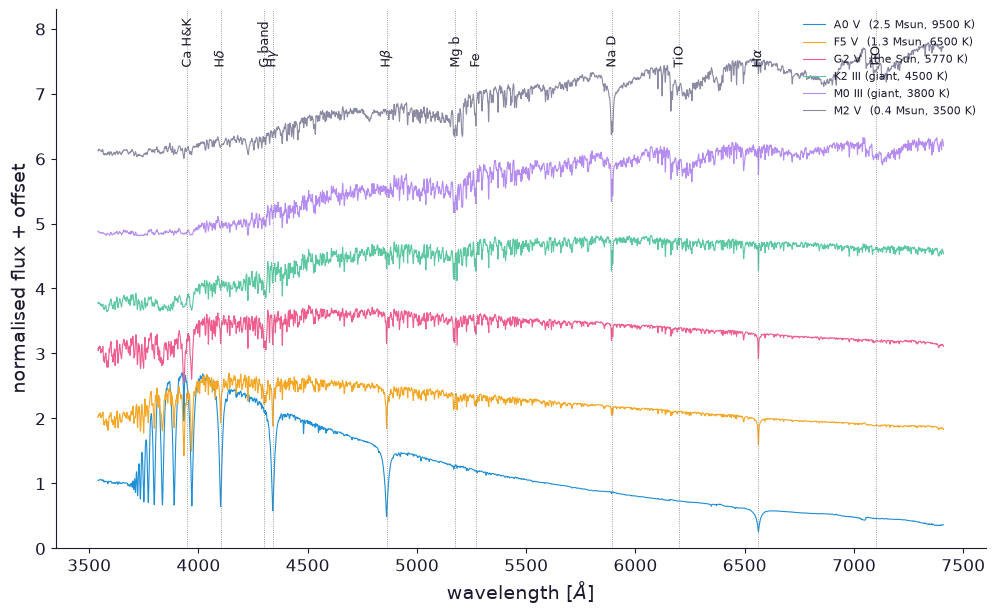

In [3]:
# (log g [cgs], T_eff [K]) of typical stars. log g ~ 4-5: dwarfs (main sequence), log g ~ 1-3: giants.
stars = {'A0 V  (2.5 Msun, 9500 K)':  (4.0, 9500),
         'F5 V  (1.3 Msun, 6500 K)':  (4.3, 6500),
         'G2 V  (the Sun, 5770 K)':   (4.44, 5772),
         'K2 III (giant, 4500 K)':    (2.5, 4500),
         'M0 III (giant, 3800 K)':    (1.5, 3800),
         'M2 V  (0.4 Msun, 3500 K)':  (4.8, 3500)}
FEATURES = {'Ca H&K': 3950, r'H$\delta$': 4102, 'G band': 4300, r'H$\gamma$': 4340, r'H$\beta$': 4861,
            'Mg b': 5175, 'Fe': 5270, 'Na D': 5893, 'TiO': 6200, r'H$\alpha$': 6563, 'TiO ': 7100}

fig, ax = plt.subplots(figsize=(12, 7))
for k, (name, (logg, teff)) in enumerate(stars.items()):
    # predict_spectrum wants arrays of log g, log10(T_eff) and [Fe/H]; it returns spectra normalised to mean flux 1
    f = np.array(ssp.predict_spectrum(jnp.array([logg]), jnp.array([np.log10(teff)]), jnp.array([0.0])))[0]
    ax.plot(wave, f / np.median(f) + 1.2 * k, lw=0.8, label=name)
for lab, x in FEATURES.items():
    ax.axvline(x, color='grey', lw=0.6, ls=':'); ax.text(x, 7.4, lab, rotation=90, ha='center', va='bottom', fontsize=9)
ax.set_xlabel(r'wavelength [$\AA$]'); ax.set_ylabel('normalised flux + offset'); ax.set_ylim(0, 8.3)
ax.legend(loc='upper right', fontsize=8)

**Look for:** deep Balmer lines only in the A and F stars; Ca H&K, the G band, Mg b and Fe growing as stars get cooler; Na D and TiO in the M stars. A galaxy spectrum is a mix of all of these, weighted by how many of each star exist (IMF) and how bright they are (isochrone).

## 2. Templates: a grid of SSPs

We now build SSPs on a grid of ages and metallicities. These will be (a) the ingredients of our synthetic galaxies and (b) the **templates** we fit them with.

In [4]:
ages = np.geomspace(0.06, 13.0, 14)               # 14 ages from 60 Myr to 13 Gyr, log-spaced (Gyr)
mets = np.array([-1.5, -1.0, -0.5, 0.0, 0.25])    # 5 metallicities [M/H]

# One FaSTAR SSP per (age, [M/H]) pair: 14 x 5 = 70 spectra, ~0.2 s each.
# Each is the spectrum of 1 Msun of stars FORMED (the IMF in FaSTAR is normalised to 1 Msun
# between 0.1 and 100 Msun), so a weight w_i in the fit = mass formed in that age/metallicity bin.
grid = np.array([[np.array(ssp.synthesize(age=float(a), met=float(m))) for m in mets] for a in ages])
SCALE = np.median(grid)                           # one common number, keeps the weights near 1

# pPXF works on a ln(lambda) grid: there a velocity dispersion is one fixed kernel (notebook 05).
ln_lam, _, velscale = log_rebin(wave, grid[0, 0])
templates = np.array([[np.interp(ln_lam, np.log(wave), grid[i, j]) for j in range(mets.size)]
                      for i in range(ages.size)]) / SCALE
templates = np.moveaxis(templates, -1, 0)         # pPXF wants the shape (n_pixels, n_ages, n_mets)
print('templates:', templates.shape, f' velscale = {velscale:.1f} km/s per pixel')

templates: (6080, 14, 5)  velscale = 36.4 km/s per pixel


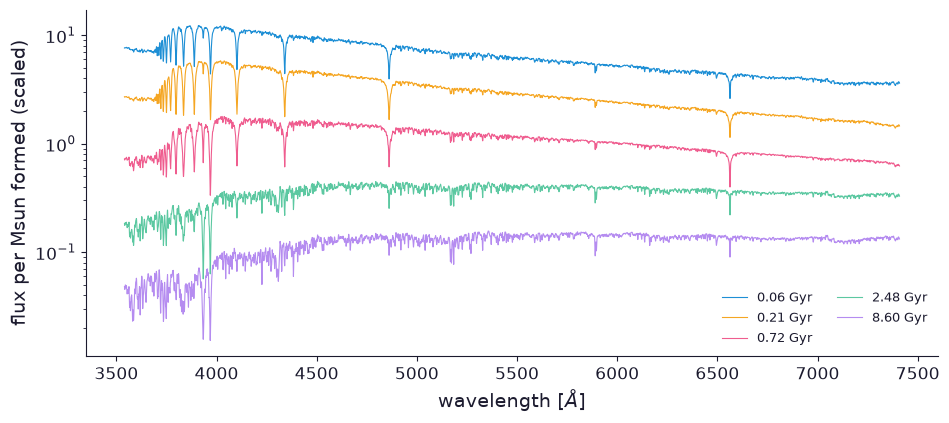

In [5]:
# How does 1 Msun of stars FADE and REDDEN with age? (same metallicity, absolute flux per Msun formed)
fig, ax = plt.subplots(figsize=(11, 4.5))
lam_t = np.exp(ln_lam)
for i in range(0, ages.size, 3):
    ax.plot(lam_t, templates[:, i, 3], lw=0.8, label=f'{ages[i]:.2f} Gyr')
ax.set_yscale('log'); ax.set_xlabel(r'wavelength [$\AA$]'); ax.set_ylabel('flux per Msun formed (scaled)')
ax.legend(fontsize=9, ncol=2)

A young SSP is ~100× brighter per unit mass than an old one: **light is dominated by the youngest stars, mass by the oldest**. That is why a small young burst can hide a big old population — and why we compare *mass-weighted* and *light-weighted* ages.

## 3. Four synthetic galaxies

We build each galaxy from a **finer** set of ages than the template grid (fitting with exactly the same templates that made the mock would be cheating — the "inverse crime").

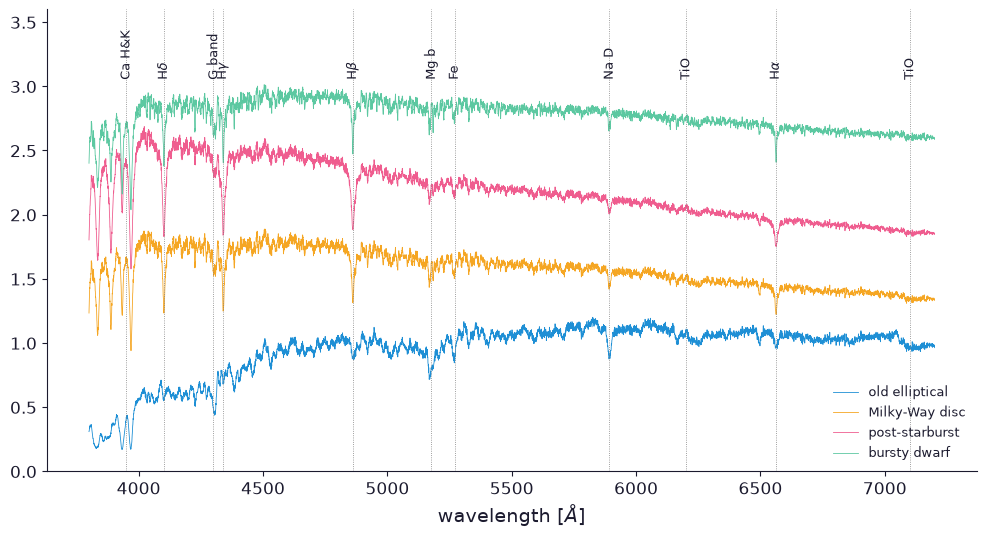

In [6]:
def make_galaxy(sfh, zfun, sigma, snr, seed=0, t_max=13.0, n=60):
    # sfh(t):  star-formation rate at lookback time t [Gyr] (arbitrary units; only the shape matters)
    # zfun(t): [M/H] of the stars born at lookback time t (an age-metallicity relation)
    # sigma:   velocity dispersion of the stars [km/s] -> broadens all lines
    # snr:     signal-to-noise ratio per pixel
    t = np.geomspace(0.05, t_max, n)          # 60 birth times between 50 Myr and 13 Gyr ago
    dt = np.gradient(t)                       # width of each time bin [Gyr]
    mass = sfh(t) * dt                        # mass formed in each bin = SFR x duration
    # the galaxy spectrum = sum over generations of (mass formed) x (SSP spectrum per Msun formed)
    spec = sum(m * np.array(ssp.synthesize(age=float(a), met=float(np.clip(zfun(a), -2.4, 0.29))))
               for a, m in zip(t, mass) if m > 0) / SCALE
    lnl, s, _ = log_rebin(wave, spec, velscale)   # to ln(lambda), same pixels as the templates
    s = broaden_velocity(s, velscale, sigma)      # the stars move: Doppler broadening
    s, noise = add_noise(s, snr, rng=seed)        # photon noise
    return dict(t=t, mass=mass / mass.sum(), z=zfun(t), lam=np.exp(lnl), flux=s, noise=noise, sigma=sigma)

galaxies = {
  # one early burst ~11.5 Gyr ago lasting ~1 Gyr, slightly metal-rich, large sigma (massive)
  'old elliptical':  make_galaxy(lambda t: np.exp(-0.5 * ((t - 11.5) / 0.7) ** 2), lambda t: 0.1 + 0 * t, sigma=250, snr=60),
  # constant SFR for 11 Gyr; old stars are metal-poor, young ones metal-rich (chemical enrichment)
  'Milky-Way disc':  make_galaxy(lambda t: (t < 11) * 1.0, lambda t: 0.1 - 0.08 * t, sigma=100, snr=60),
  # old population + a strong burst 0.6 Gyr ago that then stopped (quenched)
  'post-starburst':  make_galaxy(lambda t: np.exp(-0.5 * ((t - 11) / 1) ** 2) + 3 * np.exp(-0.5 * ((t - 0.6) / 0.1) ** 2),
                                 lambda t: 0.0 + 0 * t, sigma=150, snr=60),
  # two bursts (9 and 1.5 Gyr ago), metal-poor, small sigma (low mass)
  'bursty dwarf':    make_galaxy(lambda t: np.exp(-0.5 * ((t - 9) / 0.8) ** 2) + 0.6 * np.exp(-0.5 * ((t - 1.5) / 0.3) ** 2),
                                 lambda t: np.where(t > 4, -1.0, -0.6), sigma=40, snr=60),
}

fig, ax = plt.subplots(figsize=(12, 6))
for k, (name, g) in enumerate(galaxies.items()):
    sel = (g['lam'] > 3800) & (g['lam'] < 7200)
    ax.plot(g['lam'][sel], g['flux'][sel] / np.median(g['flux'][sel]) + 0.6 * k, lw=0.6, label=name)
for lab, x in FEATURES.items():
    ax.axvline(x, color='grey', lw=0.6, ls=':'); ax.text(x, 3.05, lab, rotation=90, ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, 3.6); ax.set_xlabel(r'wavelength [$\AA$]'); ax.legend(fontsize=9, loc='lower right')

**Read the spectra like a detective.** The post-starburst has the deepest Balmer lines (A stars from the 0.6 Gyr burst). The old elliptical has the strongest Mg b and Fe, a deep 4000 Å break and smeared-out lines ($\sigma$ = 250 km/s). The dwarf has weak metal lines (low [M/H]) but sharp ones ($\sigma$ = 40 km/s).

## 4. Who makes the light? Split a galaxy into its generations

Because the galaxy is a *sum*, we can plot each part separately: here the post-starburst, split into stars younger and older than 2 Gyr.

mass fraction in stars < 2 Gyr: 23%   light fraction at 5500 A: 78%


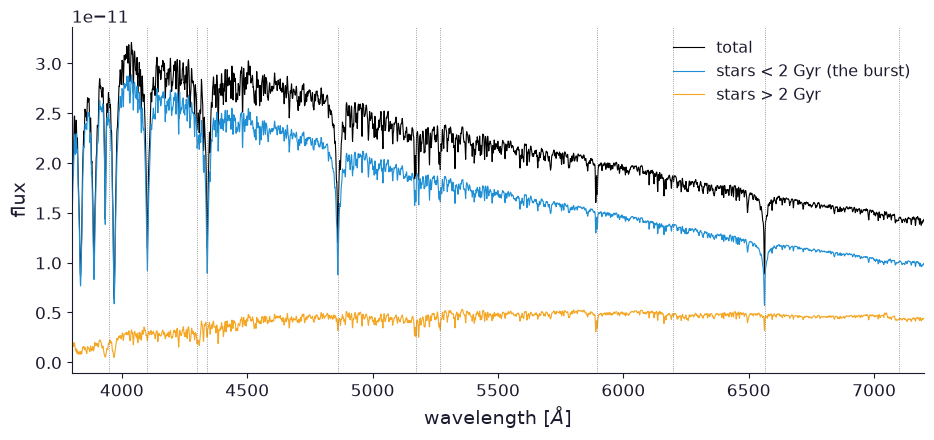

In [7]:
g = galaxies['post-starburst']
young = g['t'] < 2.0
def part(mask):
    s = sum(m * np.array(ssp.synthesize(age=float(a), met=0.0)) for a, m, ok in zip(g['t'], g['mass'], mask) if ok)
    return np.interp(ln_lam, np.log(wave), s)
f_young, f_old = part(young), part(~young)
print(f'mass fraction in stars < 2 Gyr: {g["mass"][young].sum():.0%}   '
      f'light fraction at 5500 A: {np.interp(5500, lam_t, f_young) / np.interp(5500, lam_t, f_young + f_old):.0%}')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(lam_t, f_young + f_old, 'k', lw=0.8, label='total')
ax.plot(lam_t, f_young, lw=0.8, label='stars < 2 Gyr (the burst)')
ax.plot(lam_t, f_old, lw=0.8, label='stars > 2 Gyr')
for lab, x in FEATURES.items():
    ax.axvline(x, color='grey', lw=0.6, ls=':')
ax.set_xlim(3800, 7200); ax.set_xlabel(r'wavelength [$\AA$]'); ax.set_ylabel('flux'); ax.legend()

The young stars carry a small fraction of the **mass** but a large fraction of the **light**, especially in the blue, and they make the deep Balmer lines. The old stars make the red continuum, Mg b, Fe and TiO.

## 5. Fit one galaxy with pPXF

What pPXF does: for trial kinematics (V, σ) it broadens all templates, then finds the non-negative weights that best reproduce the galaxy, and iterates on (V, σ).

* `start=[V, sigma]` — first guess of the kinematics (km/s); `moments=2` fits V and σ.
* `degree=-1` — no additive polynomial (it would mimic a featureless continuum and bias the ages).
* `mdegree=8` — a multiplicative polynomial: absorbs flux-calibration errors and dust (changes the continuum shape, not the lines).
* `regul` — regularisation strength (0 = plain non-negative least squares).
* `reg_dim` — the template grid shape (n_ages, n_mets), so pPXF knows which weights are neighbours.

sigma: fitted 151 km/s, true 150 km/s;  chi2/pixel = 0.98


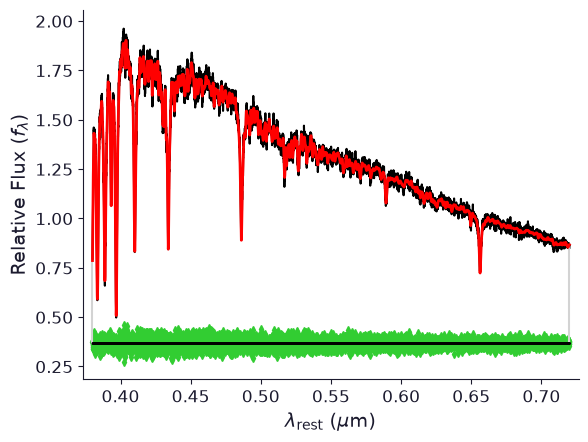

In [8]:
def fit(g, regul=0, mdegree=8, plot=False):
    sel = (g['lam'] > 3800) & (g['lam'] < 7200)          # fit range: avoid the ends of the model spectra
    pp = ppxf(templates,                                  # (n_pix, n_ages, n_mets) SSPs per Msun formed
              g['flux'][sel], g['noise'][sel],            # the data and its 1-sigma errors
              velscale, start=[0, 100], moments=2,        # fit V and sigma, starting from 0 and 100 km/s
              degree=-1, mdegree=mdegree,                 # polynomials (see above)
              lam=g['lam'][sel], lam_temp=np.exp(ln_lam), # wavelengths: pPXF works out the offsets itself
              regul=regul, reg_dim=templates.shape[1:],   # smoothness penalty on the weight grid
              quiet=True, plot=plot)
    w = pp.weights.reshape(ages.size, mets.size)          # mass formed in each (age, [M/H]) bin
    return pp, w / w.sum()                                # normalise: fractions of the total mass formed

g = galaxies['post-starburst']
pp, w = fit(g, regul=0, plot=True)
print(f'sigma: fitted {pp.sol[1]:.0f} km/s, true {g["sigma"]} km/s;  chi2/pixel = {pp.chi2:.2f}')

In the plot: black = data, red = best fit, green = residuals (offset). χ²/pixel ≈ 1 means the fit is as good as the noise allows.

## 6. Recovered vs true star-formation history

We compare the **cumulative** mass formed (from the oldest stars to today), which is much more robust than the mass in single age bins, and the mass-weighted mean age and [M/H].

regul=   0: mass-weighted age  6.34 Gyr, [M/H] -0.05  (chi2/pix 0.98)


regul=  30: mass-weighted age  3.80 Gyr, [M/H] +0.08  (chi2/pix 1.02)


regul= 300: mass-weighted age  1.10 Gyr, [M/H] +0.01  (chi2/pix 1.14)
truth     : mass-weighted age  5.56 Gyr, [M/H] +0.00


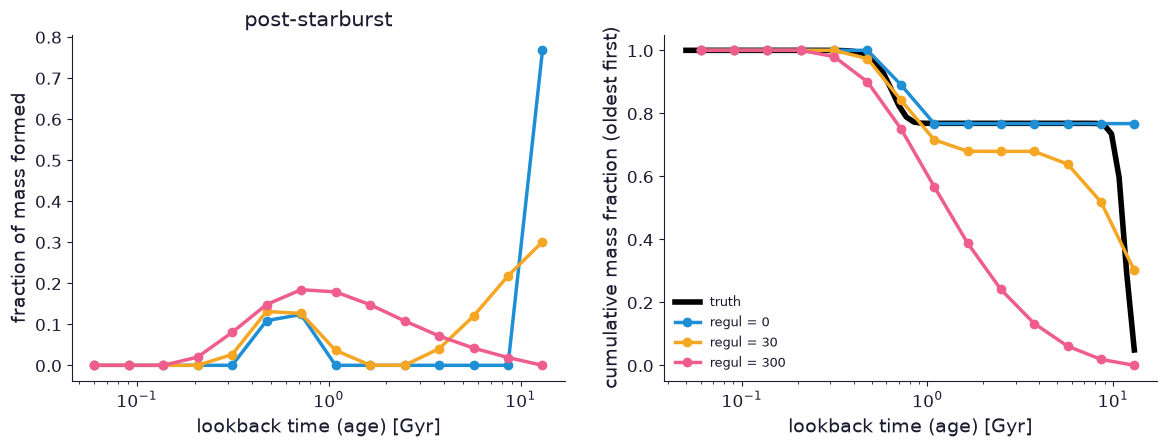

In [9]:
def compare(name, regul_values=(0, 30, 300)):
    g = galaxies[name]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
    order = np.argsort(g['t'])[::-1]                                    # oldest first
    a2.plot(g['t'][order], np.cumsum(g['mass'][order]), 'k', lw=4, label='truth')
    for regul in regul_values:
        pp, w = fit(g, regul=regul)
        m_age = w.sum(axis=1)                                           # sum over metallicity -> mass per age
        a1.plot(ages, m_age, 'o-', label=f'regul = {regul}')
        a2.plot(ages[::-1], np.cumsum(m_age[::-1]), 'o-', label=f'regul = {regul}')
        mw_age = 10 ** (m_age @ np.log10(ages))                         # mass-weighted (log) age
        mw_z = w.sum(axis=0) @ mets                                     # mass-weighted [M/H]
        print(f'regul={regul:4d}: mass-weighted age {mw_age:5.2f} Gyr, [M/H] {mw_z:+.2f}  (chi2/pix {pp.chi2:.2f})')
    print(f'truth     : mass-weighted age {10 ** (g["mass"] @ np.log10(g["t"])):5.2f} Gyr, [M/H] {g["mass"] @ g["z"]:+.2f}')
    for ax in (a1, a2):
        ax.set_xscale('log'); ax.set_xlabel('lookback time (age) [Gyr]')
    a1.set_ylabel('fraction of mass formed'); a2.set_ylabel('cumulative mass fraction (oldest first)')
    a1.set_title(name); a2.legend(fontsize=9)

compare('post-starburst')

regul=   0: mass-weighted age 12.98 Gyr, [M/H] +0.04  (chi2/pix 1.02)


regul=  30: mass-weighted age 10.76 Gyr, [M/H] +0.16  (chi2/pix 1.08)


regul= 300: mass-weighted age  9.81 Gyr, [M/H] +0.13  (chi2/pix 1.28)
truth     : mass-weighted age 11.47 Gyr, [M/H] +0.10


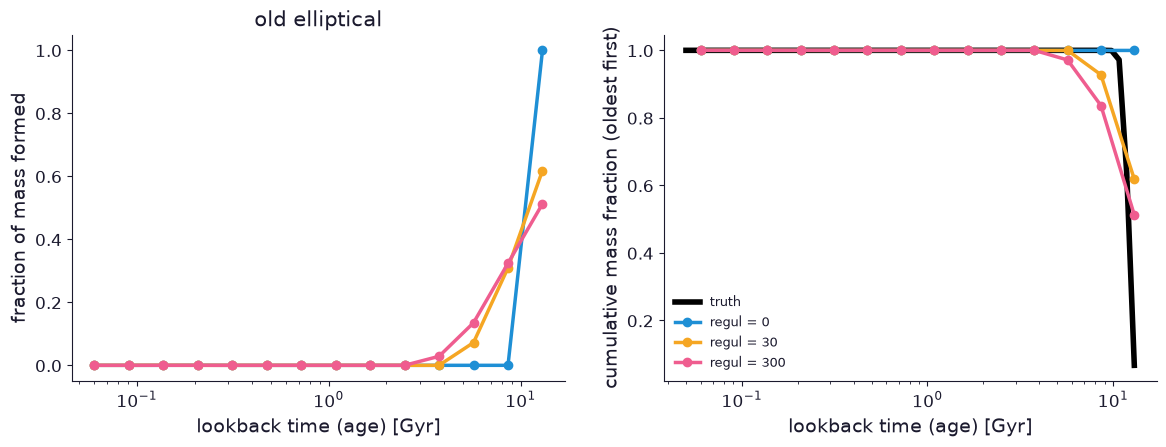

In [10]:
compare('old elliptical')

regul=   0: mass-weighted age  3.64 Gyr, [M/H] -0.37  (chi2/pix 0.98)


regul=  30: mass-weighted age  4.28 Gyr, [M/H] -0.24  (chi2/pix 0.99)


regul= 300: mass-weighted age  4.47 Gyr, [M/H] -0.26  (chi2/pix 0.99)
truth     : mass-weighted age  4.25 Gyr, [M/H] -0.35


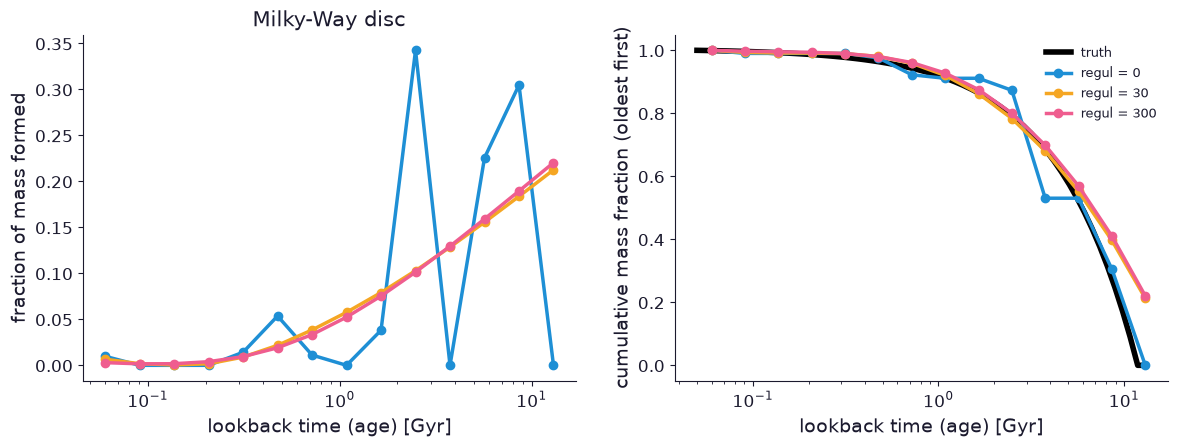

In [11]:
compare('Milky-Way disc')

regul=   0: mass-weighted age  7.34 Gyr, [M/H] -0.94  (chi2/pix 0.98)


regul=  30: mass-weighted age  7.60 Gyr, [M/H] -0.87  (chi2/pix 1.00)


regul= 300: mass-weighted age  5.65 Gyr, [M/H] -0.82  (chi2/pix 1.03)
truth     : mass-weighted age  6.43 Gyr, [M/H] -0.93


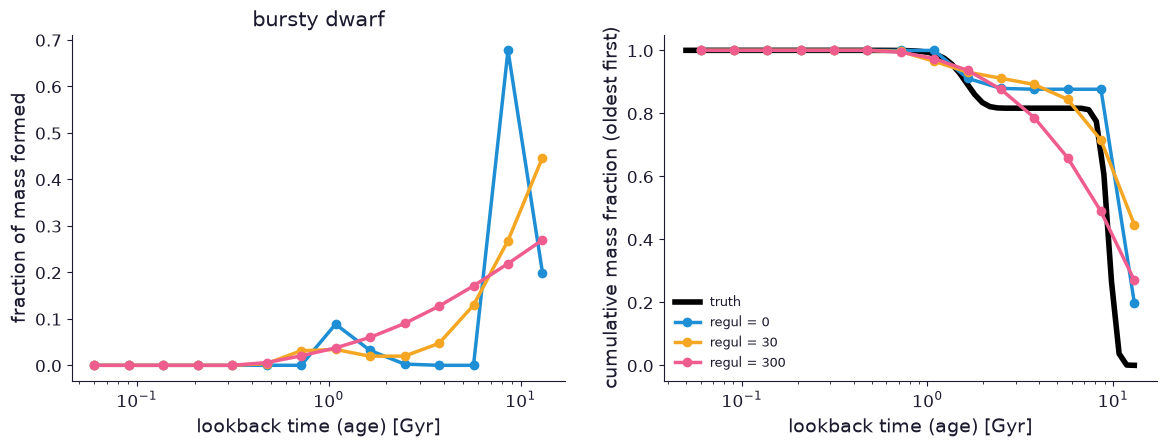

In [12]:
compare('bursty dwarf')

**How much regularisation?** Too little gives spiky, noise-driven solutions; too much smears real bursts out (look at regul = 300 for the post-starburst, and at its higher χ²). A classic recipe (Press et al.; Cappellari 2017): increase `regul` until χ² has grown by $\sqrt{2N_\mathrm{pix}}$ above the unregularised fit.

**Questions.**
* Without regularisation (`regul=0`) the solution is spiky: why does a least-squares fit love a few templates?
* Which features are recovered robustly: the young burst, the old bulk, the exact ages?
* Compare the mass-weighted [M/H] with the truth. Where does the age–metallicity degeneracy show up?

## 7. What pPXF does, by hand

With the kinematics fixed, the problem is **non-negative least squares**: find $w_i \ge 0$ minimising $\|(\mathbf{T} w - F)/\sigma\|^2$, where the columns of $\mathbf{T}$ are the broadened templates. `scipy.optimize.nnls` solves it in one line.

templates used (weight > 1%): 3 of 70


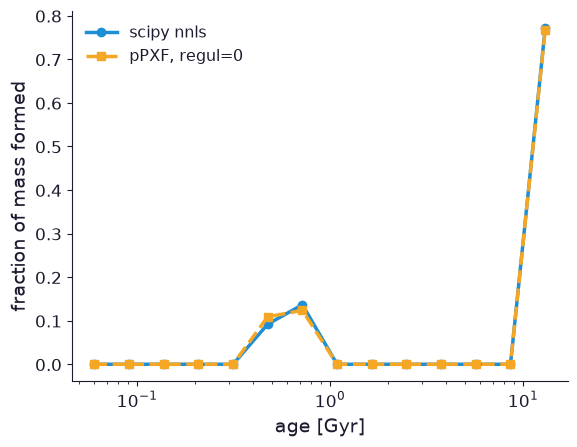

In [13]:
g = galaxies['post-starburst']
sel = (g['lam'] > 3800) & (g['lam'] < 7200)
# columns of T: every template, broadened with the true sigma, on the galaxy's pixels
T = np.array([broaden_velocity(templates[:, i, j], velscale, g['sigma'])
              for i in range(ages.size) for j in range(mets.size)]).T
T = np.array([np.interp(np.log(g['lam'][sel]), ln_lam, T[:, k]) for k in range(T.shape[1])]).T
A = T / g['noise'][sel, None]            # divide each row by the noise: chi2 = |A w - b|^2
b = g['flux'][sel] / g['noise'][sel]
w_nnls, _ = nnls(A, b)                   # the whole fit: one line
w_nnls = w_nnls.reshape(ages.size, mets.size); w_nnls /= w_nnls.sum()
print('templates used (weight > 1%):', int((w_nnls > 0.01).sum()), 'of', w_nnls.size)
plt.plot(ages, w_nnls.sum(1), 'o-', label='scipy nnls'); plt.plot(ages, fit(g, regul=0)[1].sum(1), 's--', label='pPXF, regul=0')
plt.xscale('log'); plt.xlabel('age [Gyr]'); plt.ylabel('fraction of mass formed'); plt.legend()

## Exercises

1. Lower the S/N of the post-starburst to 15 (`make_galaxy(..., snr=15)`). Is the young burst still found? Its mass? Its age?
2. Make the burst **older** (t = 2 Gyr instead of 0.6 Gyr). Why is it harder to recover? *(Hint: section 1 — which stars make the Balmer lines, and how long do they live?)*
3. Add dust: multiply the galaxy by a smooth slope, `g['flux'] *= (g['lam'] / 5500) ** 0.5`. Fit with `mdegree=0` and `mdegree=8`. What happens?
4. Build templates with a top-heavy or bottom-heavy IMF (`imf.single_power_law`, `imf_params={'alpha': ...}`) and fit the Milky-Way disc. How much does the inferred SFH depend on the IMF you assume?
5. Lecture 2 link: the SFH of the old elliptical gives its star-formation **duration**. Compare with the [Mg/Fe] ≈ +0.3 argument (Slido S2.9).